<a href="https://colab.research.google.com/github/AnanyaAsthana/Data-Mining-Warehousing-Lab/blob/main/lab10_dwm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saving 05_apriori_market_basket.csv to 05_apriori_market_basket.csv
First 5 rows:
  Transaction_ID                              Items
0           T001  Biscuits;Bread;Butter;Coffee;Milk
1           T002                        Apples;Milk
2           T003                      Cheese;Coffee
3           T004         Biscuits;Butter;Coffee;Tea
4           T005                       Bread;Butter

Transactions:
[['Biscuits', 'Bread', 'Butter', 'Coffee', 'Milk'], ['Apples', 'Milk'], ['Cheese', 'Coffee'], ['Biscuits', 'Butter', 'Coffee', 'Tea'], ['Bread', 'Butter']]

ONE HOT ENCODED DATA:
   Apples  Bananas  Biscuits  Bread  Butter  Cheese  Coffee   Eggs   Milk  \
0   False    False      True   True    True   False    True  False   True   
1    True    False     False  False   False   False   False  False   True   
2   False    False     False  False   False    True    True  False  False   
3   False    False      True  False    True   False    True  False  False   
4   False    False     Fals

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


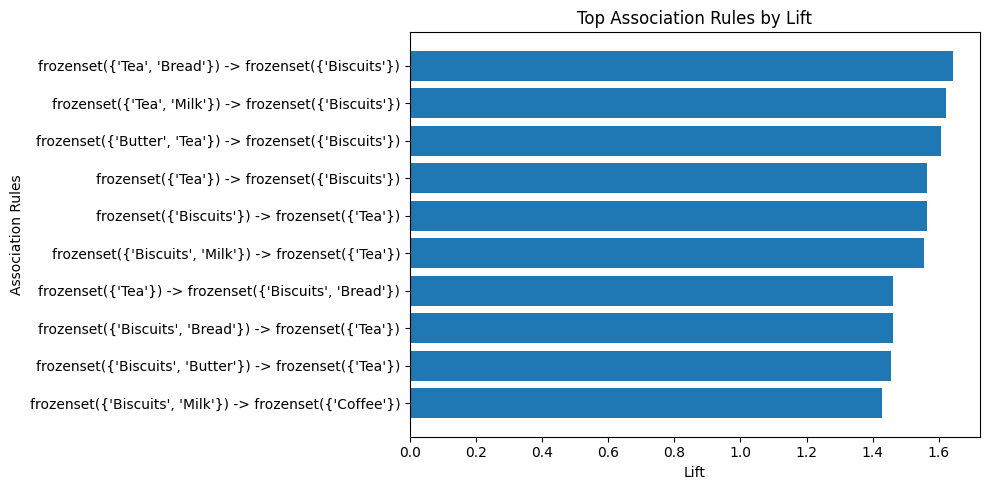


BEST ASSOCIATION RULE
Antecedent: frozenset({'Tea', 'Bread'})
Consequent: frozenset({'Biscuits'})
Support: 0.2125
Confidence: 0.9444444444444444
Lift: 1.6425120772946862

INTERPRETATION:
Support indicates how frequently the item combination occurs.
Confidence indicates how often the consequent occurs
when the antecedent occurs.
Lift indicates the strength of association between items.

CONCLUSION:
Apriori identifies frequent itemsets from transactions.
Association rules show relationships between items.
Support measures frequency.
Confidence measures rule reliability.
Lift measures the strength of association.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [1]:

# EXPERIMENT 8: APRIORI ASSOCIATION RULE MINING

# Install required library
!pip install mlxtend -q

import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

from google.colab import files

# Upload dataset
uploaded = files.upload()

df = pd.read_csv('05_apriori_market_basket.csv')

print("First 5 rows:")
print(df.head())


# 1. CONVERT TRANSACTIONS INTO LISTS

transactions = df['Items'].dropna().apply(
    lambda x: [item.strip() for item in x.split(';')]
).tolist()

print("\nTransactions:")
print(transactions[:5])


# 2. CONVERT INTO ONE-HOT ENCODING

te = TransactionEncoder()

encoded_array = te.fit(transactions).transform(transactions)

basket = pd.DataFrame(
    encoded_array,
    columns=te.columns_
)

print("\nONE HOT ENCODED DATA:")
print(basket.head())


# 3. GENERATE FREQUENT ITEMSETS
# Minimum support = 0.15

frequent_itemsets = apriori(
    basket,
    min_support=0.15,
    use_colnames=True
)

print("\nFREQUENT ITEMSETS:")
print(frequent_itemsets)


# 4. GENERATE ASSOCIATION RULES

rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.50
)

print("\nASSOCIATION RULES:")

if not rules.empty:

    print(rules[
        ['antecedents', 'consequents',
         'support', 'confidence', 'lift']
    ])

else:
    print("No rules found for the selected thresholds.")


# 5. SORT RULES BY LIFT

if not rules.empty:

    sorted_rules = rules.sort_values(
        by='lift',
        ascending=False
    )

    print("\nTOP ASSOCIATION RULES:")
    print(sorted_rules[
        ['antecedents', 'consequents',
         'support', 'confidence', 'lift']
    ].head(10))


# 6. COMPARE DIFFERENT MINIMUM SUPPORT VALUES

support_values = [0.15, 0.20, 0.25]

print("\nCOMPARISON OF SUPPORT THRESHOLDS")

for support in support_values:

    frequent = apriori(
        basket,
        min_support=support,
        use_colnames=True
    )

    print("\nMinimum Support:", support)

    print("Number of Frequent Itemsets:",
          len(frequent))

    print(frequent)


# 7. VISUALIZATION OF TOP RULES

if not rules.empty:

    top_rules = rules.sort_values(
        by='lift',
        ascending=False
    ).head(10)

    labels = [
        str(a) + " -> " + str(c)
        for a, c in zip(
            top_rules['antecedents'],
            top_rules['consequents']
        )
    ]

    plt.figure(figsize=(10, 5))

    plt.barh(
        labels,
        top_rules['lift']
    )

    plt.xlabel('Lift')
    plt.ylabel('Association Rules')
    plt.title('Top Association Rules by Lift')
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()


# 8. EXPLAIN THE BEST RULE

if not rules.empty:

    best_rule = rules.loc[rules['lift'].idxmax()]

    print("\nBEST ASSOCIATION RULE")

    print("Antecedent:", best_rule['antecedents'])
    print("Consequent:", best_rule['consequents'])

    print("Support:", best_rule['support'])
    print("Confidence:", best_rule['confidence'])
    print("Lift:", best_rule['lift'])

    print("\nINTERPRETATION:")
    print("Support indicates how frequently the item combination occurs.")
    print("Confidence indicates how often the consequent occurs")
    print("when the antecedent occurs.")
    print("Lift indicates the strength of association between items.")


# 9. CONCLUSION

print("\nCONCLUSION:")
print("Apriori identifies frequent itemsets from transactions.")
print("Association rules show relationships between items.")
print("Support measures frequency.")
print("Confidence measures rule reliability.")
print("Lift measures the strength of association.")
